In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Task 1

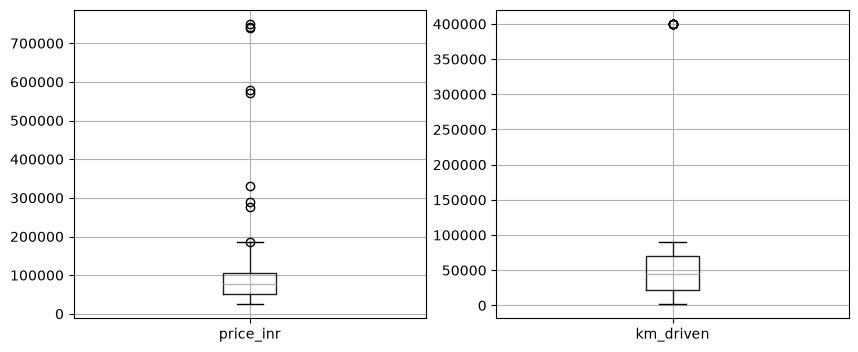

price_inr - IQR flagged: 9 | z-score flagged: 6
km_driven - IQR flagged: 6 | z-score flagged: 6


In [3]:
bikes = pd.read_csv('bike_listings_s6.csv')

np.random.seed(7)
price_idx = np.random.choice(bikes.index, 10, replace=False)
bikes.loc[price_idx, 'price_inr'] = bikes.loc[price_idx, 'price_inr'] * 6

km_idx = np.random.choice(bikes.index, 6, replace=False)
bikes.loc[km_idx, 'km_driven'] = 400000

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bikes.boxplot(column='price_inr', ax=axes[0])
bikes.boxplot(column='km_driven', ax=axes[1])
plt.show()

for col in ['price_inr', 'km_driven']:
    q1 = bikes[col].quantile(0.25)
    q3 = bikes[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_flagged = ((bikes[col] < lower) | (bikes[col] > upper)).sum()
    z = (bikes[col] - bikes[col].mean()) / bikes[col].std()
    z_flagged = (z > 3).sum()
    print(col, "- IQR flagged:", iqr_flagged, "| z-score flagged:", z_flagged)

# Task 2

In [4]:
q1 = bikes['price_inr'].quantile(0.25)
q3 = bikes['price_inr'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

bikes['price_capped'] = bikes['price_inr'].clip(lower_fence, upper_fence)

p5 = bikes['price_inr'].quantile(0.05)
p95 = bikes['price_inr'].quantile(0.95)
bikes['price_wins'] = bikes['price_inr'].clip(p5, p95)

bikes['km_log'] = np.log1p(bikes['km_driven'])

summary = bikes[['price_inr', 'price_capped', 'price_wins', 'km_driven', 'km_log']].agg(['max', 'mean']).T
print(summary)
print("Rows:", len(bikes))

                        max          mean
price_inr     749916.000000  88129.710000
price_capped  186314.375000  81152.018437
price_wins    131626.800000  79868.845000
km_driven     400000.000000  51053.322500
km_log            12.899222     10.492936
Rows: 400


# Task 3

In [5]:
bikes_typed = bikes.copy()
before_memory = bikes_typed.memory_usage(deep=True).sum()
print("Dtypes before:")
print(bikes_typed.dtypes)

bikes_typed['price_inr'] = bikes_typed['price_inr'].round().astype(int).map('Rs {:,}'.format)
print(bikes_typed['price_inr'].head())

bikes_typed['price_inr'] = bikes_typed['price_inr'].str.replace('Rs ', '').str.replace(',', '')
bikes_typed['price_inr'] = pd.to_numeric(bikes_typed['price_inr'], errors='coerce')

bikes_typed['brand'] = bikes_typed['brand'].astype('category')
bikes_typed['city'] = bikes_typed['city'].astype('category')
bikes_typed['owner_count'] = bikes_typed['owner_count'].astype('int8')
bikes_typed['is_first_owner'] = bikes_typed['owner_count'] == 1

after_memory = bikes_typed.memory_usage(deep=True).sum()
print("Dtypes after:")
print(bikes_typed.dtypes)
print("Memory before:", before_memory)
print("Memory after:", after_memory)

Dtypes before:
listing_id        int64
brand               str
city                str
model_year        int64
km_driven       float64
owner_count     float64
price_inr       float64
price_capped    float64
price_wins      float64
km_log          float64
dtype: object
0     Rs 51,958
1    Rs 102,539
2     Rs 90,128
3     Rs 50,963
4     Rs 50,963
Name: price_inr, dtype: str
Dtypes after:
listing_id           int64
brand             category
city              category
model_year           int64
km_driven          float64
owner_count           int8
price_inr            int64
price_capped       float64
price_wins         float64
km_log             float64
is_first_owner        bool
dtype: object
Memory before: 70195
Memory after: 24577


# Task 4

In [6]:
np.random.seed(7)
n = len(bikes_typed)

dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(np.random.randint(0, 366, n), unit='D')
use_slash = np.random.rand(n) < 0.6

listed_text = np.where(use_slash, dates.strftime('%d/%m/%Y'), dates.strftime('%d-%b-%Y'))
bikes_typed['listed_on'] = listed_text
print(bikes_typed['listed_on'].head())

slash_dates = pd.to_datetime(bikes_typed['listed_on'], format='%d/%m/%Y', errors='coerce')
dash_dates = pd.to_datetime(bikes_typed['listed_on'], format='%d-%b-%Y', errors='coerce')
bikes_typed['listed_on'] = slash_dates.fillna(dash_dates)

print("NaT count:", bikes_typed['listed_on'].isna().sum())
bikes_typed['listed_month'] = bikes_typed['listed_on'].dt.month

print(bikes_typed[['listed_on', 'listed_month']].head())
bikes_typed.to_csv('bike_listings_s7.csv', index=False)

0     24/06/2024
1    15-Jul-2024
2     26/01/2024
3     08/03/2024
4    30-Jul-2024
Name: listed_on, dtype: str
NaT count: 0
   listed_on  listed_month
0 2024-06-24             6
1 2024-07-15             7
2 2024-01-26             1
3 2024-03-08             3
4 2024-07-30             7
